<a href="https://colab.research.google.com/github/AdityaJare/ML-PRojects/blob/main/vehical_classification_CNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import tensorflow as tf
print(tf.config.list_physical_devices("GPU"))

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [3]:
!pip install -q --upgrade kaggle

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.2/126.2 kB 1.8 MB/s eta 0:00:00


In [4]:
import os
from google.colab import userdata

os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")
print("token loaded:", len(os.environ["KAGGLE_API_TOKEN"]) > 0)

token loaded: True


In [5]:
!kaggle datasets download -d ilhamhasib/vehicle-classification-dataset -p /content/data --unzip

Dataset URL: https://www.kaggle.com/datasets/ilhamhasib/vehicle-classification-dataset
License(s): CC-BY-SA-4.0
100% 4.38G/4.38G [00:43<00:00, 107MB/s] 



In [6]:
for root, dirs, files in os.walk("/content/data"):
    print(root, "|", len(dirs), "folders,", len(files), "files")
    if root.count(os.sep) - "/content/data".count(os.sep) >= 2:
        break

/content/data | 2 folders, 0 files
/content/data/Vehicle Test Data | 10 folders, 0 files
/content/data/Vehicle Test Data/MPV | 0 folders, 10 files


In [7]:
import os, pandas as pd, tensorflow as tf
from sklearn.model_selection import train_test_split

In [8]:
labels = pd.read_csv("/content/data/Car-Classification-Data-with-Labels-iHasib/type-labels.csv")

In [9]:
labels

,ID,Type
0,0,Bike
1,1,Bike
2,2,Bike
3,3,Bike
4,4,Bike
...,...,...
6475,6475,Bus
6476,6476,Bus
6477,6477,Bus
6478,6478,Bus


Bus


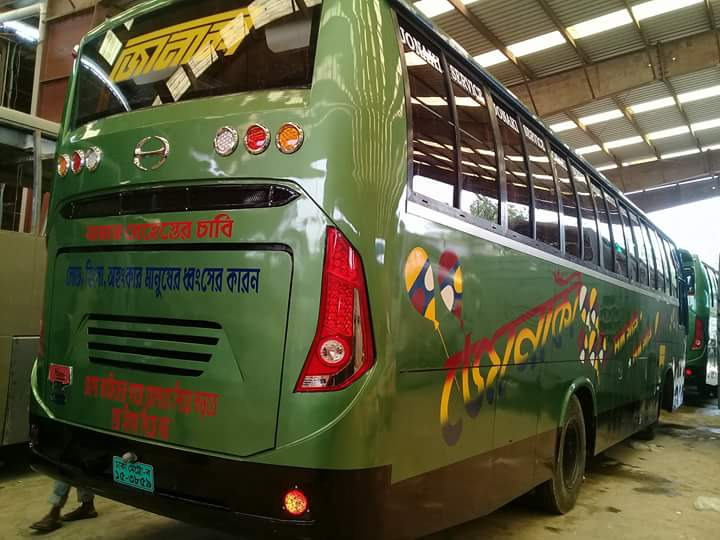

In [10]:
import cv2
from google.colab.patches import cv2_imshow
print(labels["Type"][6479])
img = cv2.imread("/content/data/Car-Classification-Data-with-Labels-iHasib/Train/6479.jpg")
cv2_imshow(img)

In [11]:
labels["Type"] = labels["Type"].str.upper()


In [12]:
labels["Path"] = "/content/data/Car-Classification-Data-with-Labels-iHasib/Train/" + labels["ID"].astype(str) + ".jpg"

In [13]:
labels.head()

,ID,Type,Path
0,0,BIKE,/content/data/Car-Classification-Data-with-Lab...
1,1,BIKE,/content/data/Car-Classification-Data-with-Lab...
2,2,BIKE,/content/data/Car-Classification-Data-with-Lab...
3,3,BIKE,/content/data/Car-Classification-Data-with-Lab...
4,4,BIKE,/content/data/Car-Classification-Data-with-Lab...


In [14]:
class_names = sorted(labels["Type"].unique())

In [15]:
class_names

['BIKE',
 'BUS',
 'CNG',
 'EASY-BIKE',
 'HATCHBACK',
 'MPV',
 'PICKUP',
 'SEDAN',
 'SUV',
 'TRUCK']

In [16]:
labels["y"] = labels["Type"].map({c: i for i, c in enumerate(class_names)})

In [17]:
labels.head()

,ID,Type,Path,y
0,0,BIKE,/content/data/Car-Classification-Data-with-Lab...,0
1,1,BIKE,/content/data/Car-Classification-Data-with-Lab...,0
2,2,BIKE,/content/data/Car-Classification-Data-with-Lab...,0
3,3,BIKE,/content/data/Car-Classification-Data-with-Lab...,0
4,4,BIKE,/content/data/Car-Classification-Data-with-Lab...,0


In [18]:
X = labels["Path"].values
Y = labels["y"].values

In [19]:
x_train, x_val, y_train, y_val = train_test_split(
    X, Y, test_size=0.2, random_state=42, stratify = labels['y']
)

In [20]:
def load (path , label):
  img = tf.io.read_file(path)
  img = tf.image.decode_jpeg(img, channels=3)
  img = tf.image.resize(img, (224, 224))

  return img, label

In [21]:
train_ds = tf. data.Dataset.from_tensor_slices((x_train, y_train)).shuffle(len(x_train), seed=42).map(load).batch(32)
val_ds = tf.data.Dataset.from_tensor_slices((x_val, y_val)).map(load).batch(32)

In [22]:
for x, y in train_ds.take(1):
    print(x.shape, y[:5].numpy())

(32, 224, 224, 3) [5 5 8 1 3]


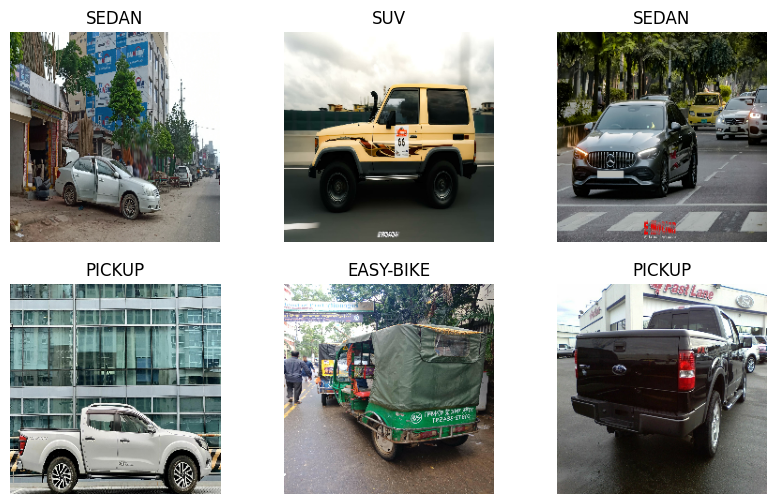

In [23]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
for x, y in train_ds.take(1):
    for i in range(6):
        plt.subplot(2, 3, i + 1)
        plt.imshow(x[i].numpy().astype("uint8"))
        plt.title(class_names[y[i]])
        plt.axis("off")
plt.show()

In [24]:
from tensorflow import keras
from keras import layers

In [25]:
num_classes = len(class_names)
print(f" Total class : {num_classes}")

 Total class : 10



Transfer Learning


In [26]:
conv_base = keras.applications.MobileNetV2(
    weights="imagenet",
    input_shape=(224, 224, 3),
    include_top=False
)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [27]:
conv_base.trainable = False

In [28]:
input = keras.Input(shape=(224, 224, 3))

aug1 = layers.RandomFlip("horizontal")(input)
aug2 = layers.RandomRotation(0.1)(aug1)
aug3 = layers.RandomZoom(0.1)(aug2)

x = layers.Rescaling(1. / 127.5, offset=-1)(aug3)

x = conv_base(x, training=False)
x = layers.GlobalAvgPool2D()(x)
x = layers.Dropout(0.2)(x)

output = layers.Dense(num_classes, activation="softmax")(x)

model = keras.Model(input, output)

In [29]:
model.compile(optimizer=keras.optimizers.Adam(1e-3),
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])

history = model.fit(train_ds, validation_data=val_ds, epochs=5)

Epoch 1/5
162/162 ━━━━━━━━━━━━━━━━━━━━ 164s 957ms/step - accuracy: 0.5802 - loss: 1.2100 - val_accuracy: 0.7731 - val_loss: 0.6703
Epoch 2/5
162/162 ━━━━━━━━━━━━━━━━━━━━ 150s 924ms/step - accuracy: 0.7253 - loss: 0.7623 - val_accuracy: 0.7770 - val_loss: 0.5782
Epoch 3/5
162/162 ━━━━━━━━━━━━━━━━━━━━ 143s 885ms/step - accuracy: 0.7554 - loss: 0.6805 - val_accuracy: 0.8025 - val_loss: 0.5567
Epoch 4/5
162/162 ━━━━━━━━━━━━━━━━━━━━ 150s 929ms/step - accuracy: 0.7861 - loss: 0.6168 - val_accuracy: 0.8241 - val_loss: 0.4937
Epoch 5/5
162/162 ━━━━━━━━━━━━━━━━━━━━ 142s 877ms/step - accuracy: 0.7973 - loss: 0.5800 - val_accuracy: 0.8187 - val_loss: 0.5009


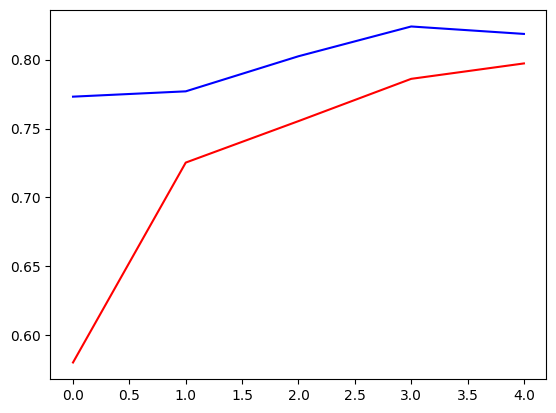

In [30]:
plt.plot(history.history["accuracy"], color="red", label="Accuracy")
plt.plot(history.history["val_accuracy"], color="blue", label="Val Accuracy")

Transfer learning with trainable last layers of pretrained model

In [32]:
base = keras.applications.MobileNetV2(
    weights = "imagenet",
    include_top=False,
    input_shape = (224, 224, 3)
)

In [33]:
base.trainable = True

for layer in base.layers:
    layer.trainable = False
base.get_layer("Conv_1").trainable = True

In [34]:
base.summary()

Model: "mobilenetv2_1.00_224"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 112, 112,  │        864 │ input_layer_2[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 112, 112,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 112, 112,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 112, 112,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 112, 112,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 112, 112,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 113, 113,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 56, 56,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 56, 56,    │      2,304 │ block_1_depthwis

 Total params: 2,257,984 (8.61 MB)

 Trainable params: 409,600 (1.56 MB)

 Non-trainable params: 1,848,384 (7.05 MB)

In [35]:
base.output_shape

(None, 7, 7, 1280)

In [36]:
inputs = keras.layers.Input(shape=(224, 224, 3))

aug1  =layers.RandomFlip("horizontal")(inputs)
aug2 = layers.RandomRotation(0.1)(aug1)
aug3 = layers.RandomZoom(0.1)(aug2)

x = layers.Rescaling(1. / 127.5, offset=-1)(aug3)

x = base(x, training=False)

globalavg = keras.layers.GlobalAveragePooling2D()(x)  #converting (7, 7, 1280) -----> (1280,)

hidden1 = keras.layers.Dense(256, activation="relu" )(globalavg)
drop1 = keras.layers.Dropout(0.1)(hidden1)

hidden2 = keras.layers.Dense(128, activation="relu")(drop1)
drop2= keras.layers.Dropout(0.1)(hidden2)

outputs = keras.layers.Dense(10, activation="softmax")(drop2)

model = keras.Model(inputs, outputs)

In [37]:
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip_1 (RandomFlip)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation_1               │ (None, 224, 224, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom_1 (RandomZoom)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,620,106 (9.99 MB)

 Trainable params: 771,722 (2.94 MB)

 Non-trainable params: 1,848,384 (7.05 MB)

In [38]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [39]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

early_stop = EarlyStopping(monitor='val_loss', patience=3)

checkpoint = ModelCheckpoint(
    filepath='/content/drive/MyDrive/best_model.keras',
    monitor='val_loss', save_best_only=True)


In [40]:
history = model.fit(train_ds, epochs=20, validation_data=val_ds, callbacks=[early_stop, checkpoint])

Epoch 1/20
162/162 ━━━━━━━━━━━━━━━━━━━━ 140s 811ms/step - accuracy: 0.5831 - loss: 1.2196 - val_accuracy: 0.7515 - val_loss: 0.7076
Epoch 2/20
162/162 ━━━━━━━━━━━━━━━━━━━━ 131s 808ms/step - accuracy: 0.7326 - loss: 0.7331 - val_accuracy: 0.8102 - val_loss: 0.5512
Epoch 3/20
162/162 ━━━━━━━━━━━━━━━━━━━━ 141s 872ms/step - accuracy: 0.7851 - loss: 0.6100 - val_accuracy: 0.8156 - val_loss: 0.5045
Epoch 4/20
162/162 ━━━━━━━━━━━━━━━━━━━━ 149s 923ms/step - accuracy: 0.8090 - loss: 0.5436 - val_accuracy: 0.8218 - val_loss: 0.4783
Epoch 5/20
162/162 ━━━━━━━━━━━━━━━━━━━━ 124s 762ms/step - accuracy: 0.8272 - loss: 0.4919 - val_accuracy: 0.8333 - val_loss: 0.4575
Epoch 6/20
162/162 ━━━━━━━━━━━━━━━━━━━━ 146s 904ms/step - accuracy: 0.8465 - loss: 0.4383 - val_accuracy: 0.8465 - val_loss: 0.4200
Epoch 7/20
162/162 ━━━━━━━━━━━━━━━━━━━━ 221s 1s/step - accuracy: 0.8621 - loss: 0.4093 - val_accuracy: 0.8418 - val_loss: 0.4454
Epoch 8/20
162/162 ━━━━━━━━━━━━━━━━━━━━ 210s 1s/step - accuracy: 0.8760 - loss:

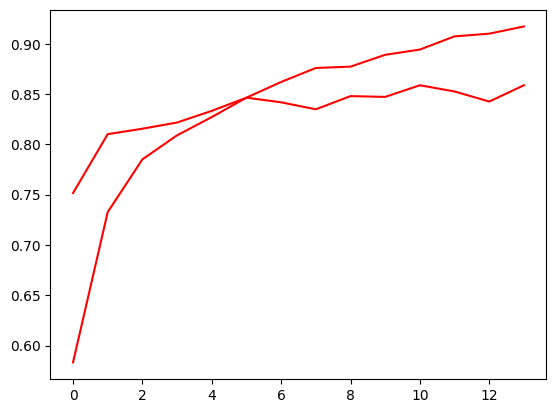

In [41]:
plt.plot(history.history["accuracy"], color="red", label="Accuracy")
plt.plot(history.history["val_accuracy"], color="red", label="Val Accuracy")

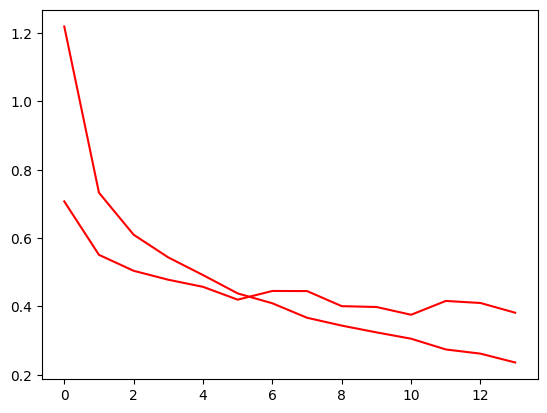

In [43]:
plt.plot(history.history["loss"], color="red", label="loss")
plt.plot(history.history["val_loss"], color="red", label="Val loss")

In [59]:
import os, tensorflow as tf

TEST_DIR = "/content/data/Vehicle Test Data"
class_to_idx = {c: i for i, c in enumerate(class_names)}

In [62]:
p_test, y_test = [], []
for folder in sorted(os.listdir(TEST_DIR)):
    for f in sorted(os.listdir(f"{TEST_DIR}/{folder}")):
        p_test.append(f"{TEST_DIR}/{folder}/{f}")
        y_test.append(class_to_idx[folder.upper()])


In [66]:
def load_any(path, label):
    img = tf.io.read_file(path)
    img = tf.image.decode_image(img, channels=3, expand_animations=False)
    img = tf.image.resize(img, (224, 224))
    return img, label

In [67]:
test_ds = tf.data.Dataset.from_tensor_slices((p_test, y_test)).map(load_any).batch(32)

In [68]:
test_ds

<_BatchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))>

In [69]:
from sklearn.metrics import classification_report, confusion_matrix

best = keras.models.load_model('/content/drive/MyDrive/best_model.keras')
print(best.evaluate(val_ds))
print(best.evaluate(test_ds))


41/41 ━━━━━━━━━━━━━━━━━━━━ 31s 627ms/step - accuracy: 0.8588 - loss: 0.3758
[0.37576839327812195, 0.8587962985038757]
4/4 ━━━━━━━━━━━━━━━━━━━━ 2s 271ms/step - accuracy: 0.7100 - loss: 1.0594
[1.0593591928482056, 0.7099999785423279]


In [70]:
y_pred = np.argmax(best.predict(test_ds), axis=1)
print(classification_report(y_test, y_pred, target_names=class_names))
print(confusion_matrix(y_test, y_pred))

4/4 ━━━━━━━━━━━━━━━━━━━━ 5s 657ms/step
              precision    recall  f1-score   support

        BIKE       1.00      1.00      1.00        10
         BUS       0.83      1.00      0.91        10
         CNG       1.00      0.80      0.89        10
   EASY-BIKE       1.00      0.80      0.89        10
   HATCHBACK       0.36      0.50      0.42        10
         MPV       0.89      0.80      0.84        10
      PICKUP       0.40      0.20      0.27        10
       SEDAN       0.44      0.40      0.42        10
         SUV       0.75      0.60      0.67        10
       TRUCK       0.59      1.00      0.74        10

    accuracy                           0.71       100
   macro avg       0.73      0.71      0.70       100
weighted avg       0.73      0.71      0.70       100

[[10  0  0  0  0  0  0  0  0  0]
 [ 0 10  0  0  0  0  0  0  0  0]
 [ 0  1  8  0  0  0  1  0  0  0]
 [ 0  0  0  8  0  0  1  0  0  1]
 [ 0  0  0  0  5  0  0  4  1  0]
 [ 0  0  0  0  2  8  0  0  0  0]
 [ 0

test on random online image

Saving ftodne-3FuQylRWQeg-unsplash.jpg to ftodne-3FuQylRWQeg-unsplash.jpg


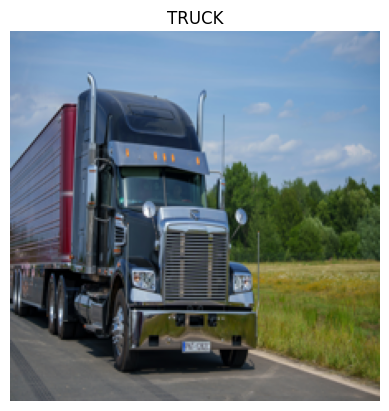

TRUCK        96.9%
SUV          1.4%
BUS          0.7%


In [73]:
from google.colab import files
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

up = files.upload()
name = list(up.keys())[0]

img = Image.open(name).convert("RGB").resize((224, 224))
probs = best.predict(np.expand_dims(np.array(img), 0), verbose=0)[0]
top = probs.argsort()[::-1][:3]

plt.imshow(img); plt.axis("off"); plt.title(class_names[top[0]]); plt.show()
for i in top:
    print(f"{class_names[i]:12s} {probs[i]:.1%}")

Saving 11.jpg to 11 (1).jpg


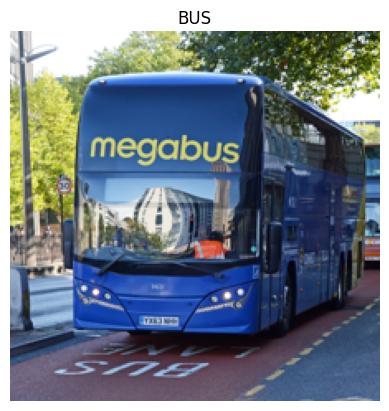

BUS          100.0%
TRUCK        0.0%
CNG          0.0%


In [74]:
from google.colab import files
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

up = files.upload()
name = list(up.keys())[0]

img = Image.open(name).convert("RGB").resize((224, 224))
probs = best.predict(np.expand_dims(np.array(img), 0), verbose=0)[0]
top = probs.argsort()[::-1][:3]

plt.imshow(img); plt.axis("off"); plt.title(class_names[top[0]]); plt.show()
for i in top:
    print(f"{class_names[i]:12s} {probs[i]:.1%}")

Saving evan-middleton-HVoco6yUXCU-unsplash.jpg to evan-middleton-HVoco6yUXCU-unsplash.jpg


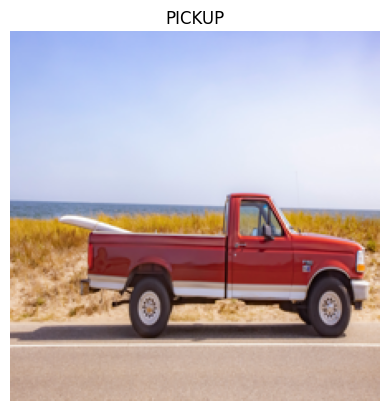

PICKUP       94.2%
MPV          3.9%
SUV          0.9%


In [77]:
from google.colab import files
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

up = files.upload()
name = list(up.keys())[0]

img = Image.open(name).convert("RGB").resize((224, 224))
probs = best.predict(np.expand_dims(np.array(img), 0), verbose=0)[0]
top = probs.argsort()[::-1][:3]

plt.imshow(img); plt.axis("off"); plt.title(class_names[top[0]]); plt.show()
for i in top:
    print(f"{class_names[i]:12s} {probs[i]:.1%}")